# Stochastic SINDy (SSISDE): Black–Scholes experiment

Run all cells from a fresh Python 3.10–3.12 kernel (tested locally with 3.11).
The original scientific code is preserved in `data_generation/`, `models/`, and
the experiment cells below. `%run -i` runs each script in this notebook's shared
namespace, maintaining the original cell order and global variables.

Local VS Code: select `.venv/bin/python`. Colab in VS Code: select **Colab → Auto
Connect**. A remote runtime needs its own copy of the scripts; the setup cell
downloads the private repository when it is not already present, asking for a
GitHub token through a hidden input. Use a fine-grained token with read-only
Contents access to `munawarali93/SSISDE`. Do not paste a token into a code cell.
An existing runtime checkout is reused; restart/delete it to fetch newer code.

Figures keep their original filenames and are saved in `experiments/black_scholes/`.
The untouched input notebook is in `original/`. See `README.md` for setup details.


In [1]:
from pathlib import Path
import os
import sys

if not (3, 10) <= sys.version_info[:2] < (3, 13):
    raise RuntimeError("The original dependency pins require Python 3.10–3.12; use the local .venv or a compatible Colab runtime.")

def _find_project():
    for candidate in [Path.cwd(), *Path.cwd().parents, Path('/content/SSISDE')]:
        if (candidate / 'models/stochastic_sindy.py').is_file() and (candidate / 'requirements.txt').is_file():
            return candidate
    return None

PROJECT_ROOT = _find_project()
if PROJECT_ROOT is None:
    import importlib.util
    try:
        _in_colab = importlib.util.find_spec('google.colab') is not None
    except ModuleNotFoundError:
        _in_colab = False
    if not _in_colab:
        raise FileNotFoundError("Open this notebook from the SSISDE checkout so its Python scripts are available.")

    def _download_private_project():
        from getpass import getpass
        from io import BytesIO
        from urllib.request import Request, urlopen
        from zipfile import ZipFile
        token = getpass('GitHub token (read-only Contents access to SSISDE): ')
        try:
            request = Request(
                'https://api.github.com/repos/munawarali93/SSISDE/zipball/main',
                headers={'Authorization': f'Bearer {token}', 'Accept': 'application/vnd.github+json'},
            )
            with urlopen(request, timeout=120) as response:
                archive_bytes = response.read()
        finally:
            token = None
            request = None
        destination = Path('/content/SSISDE')
        with ZipFile(BytesIO(archive_bytes)) as archive:
            for member in archive.infolist():
                relative = Path(*Path(member.filename).parts[1:])
                if member.is_dir() or not relative.parts:
                    continue
                target = (destination / relative).resolve()
                if not target.is_relative_to(destination.resolve()):
                    raise ValueError('Unsafe archive path')
                target.parent.mkdir(parents=True, exist_ok=True)
                target.write_bytes(archive.read(member))
        return destination

    PROJECT_ROOT = _download_private_project()

os.chdir(PROJECT_ROOT / 'experiments/black_scholes')
print(f'Project: {PROJECT_ROOT}')
print(f'Python: {sys.version.split()[0]}')


Project: /Users/munawarali/Documents/GitHub/SSISDE
Python: 3.11.13


##Install libraries

In [2]:
# Install into the selected kernel before importing scientific libraries.
# The four original version pins are retained in requirements.txt.
import subprocess
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-r', str(PROJECT_ROOT / 'requirements.txt')])



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: /Users/munawarali/Documents/GitHub/SSISDE/.venv/bin/python -m pip install --upgrade pip


0

##Import libraries

In [3]:
import numpy as np
import math
import matplotlib.pyplot as plt
import pysindy as ps
import random
import iisignature
from sklearn import linear_model
from sklearn.metrics import mean_squared_error
from tqdm import tqdm
from sklearn.linear_model import Lasso, ElasticNet
from sklearn.model_selection import TimeSeriesSplit

Matplotlib is building the font cache; this may take a moment.


/Users/munawarali/Documents/GitHub/SSISDE/.venv/lib/python3.11/site-packages/pysindy/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound


##Defining parameters and simulating noise

In [4]:
%run -i ../../data_generation/parameters.py


##Simulating primary processes

## $$dS_t = \mu(S_t)dt + \sigma(S_t)dB_t$$

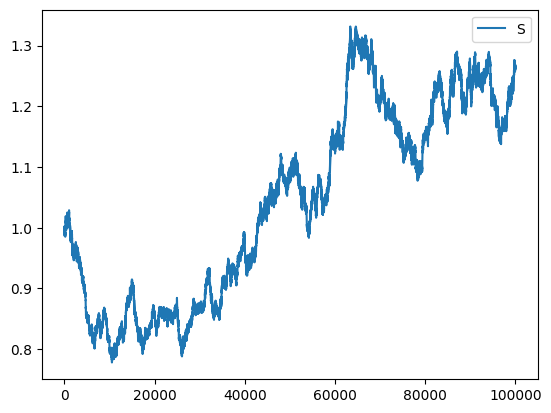

In [5]:
%run -i ../../data_generation/processes.py
plt.plot(S_, label="S")
plt.legend()
plt.show()

##compute quadratic variation

  0%|          | 0/100000 [00:00<?, ?it/s]

 14%|█▍        | 13880/100000 [00:00<00:00, 138782.26it/s]

 28%|██▊       | 27759/100000 [00:00<00:00, 88632.39it/s] 

 38%|███▊      | 37635/100000 [00:00<00:00, 69467.06it/s]

 45%|████▌     | 45331/100000 [00:00<00:00, 58442.60it/s]

...

 92%|█████████▏| 92329/100000 [00:02<00:00, 23155.65it/s]

 95%|█████████▍| 94620/100000 [00:02<00:00, 22430.07it/s]

 97%|█████████▋| 96843/100000 [00:02<00:00, 21747.95it/s]

 99%|█████████▉| 99002/100000 [00:02<00:00, 21185.84it/s]

100%|██████████| 100000/100000 [00:02<00:00, 36025.00it/s]

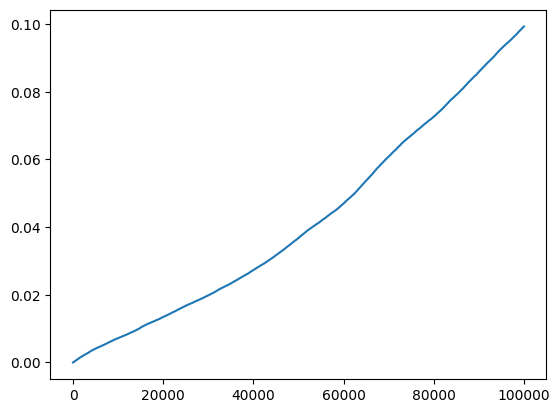

In [6]:
%run -i ../../models/quadratic_variation.py
plt.plot(QV)

##Approximating $\sigma$

In [7]:
%run -i ../../models/diffusion.py


['0.091 x0^2 + -0.002 x0^3']


/Users/munawarali/Documents/GitHub/SSISDE/.venv/lib/python3.11/site-packages/pysindy/optimizers/sr3.py:390: ConvergenceWarning: SR3._reduce did not converge after 1500 iterations.
  warnings.warn(


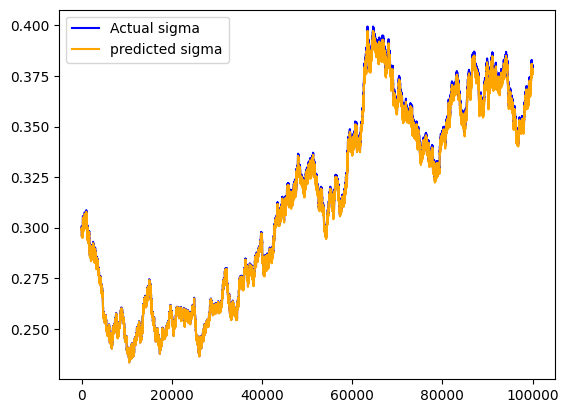

In [8]:
sigma_pred_ = np.sqrt(model.predict(S_.reshape(-1, 1)))
sigma_pred_ = np.array(sigma_pred_)
plt.plot(sigma_exact_, label="Actual sigma",color="blue")
plt.plot(sigma_pred_,label="predicted sigma", color="orange")
plt.legend()
plt.show()

In [9]:
%run -i ../../models/diffusion_derivatives.py


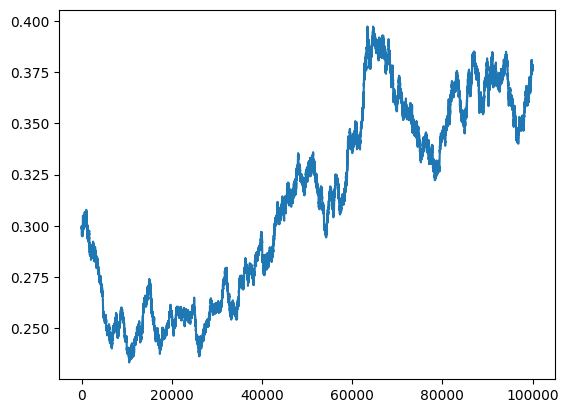

In [10]:
plt.plot(sigma_pred_)

##Q Brownian motion

/Users/munawarali/Documents/GitHub/SSISDE/models/q_brownian_motion.py:3: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  BQ_[i] = BQ_[i-1] + (S_[i] - S_[i-1])/sigma_pred_[i-1]


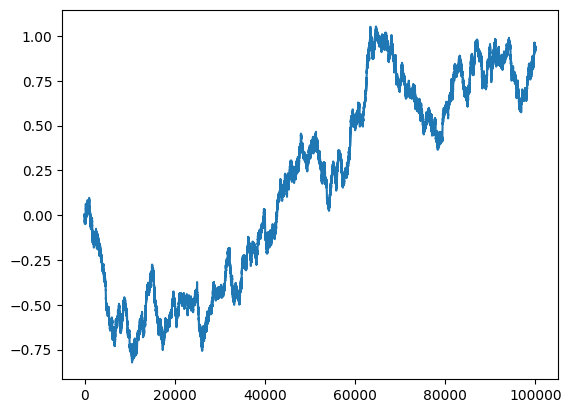

In [11]:
%run -i ../../models/q_brownian_motion.py
plt.plot(BQ_)

#Fit signature model

In [12]:
keep_cols = [0, 1, 3, 4, 5, 13]

  0%|          | 0/1000 [00:00<?, ?it/s]

 20%|██        | 205/1000 [00:00<00:00, 2044.54it/s]

 41%|████      | 410/1000 [00:00<00:00, 2020.29it/s]

 62%|██████▏   | 617/1000 [00:00<00:00, 2041.73it/s]

 82%|████████▏ | 823/1000 [00:00<00:00, 2047.59it/s]

100%|██████████| 1000/1000 [00:00<00:00, 2044.94it/s]

3.529074918675349e-05

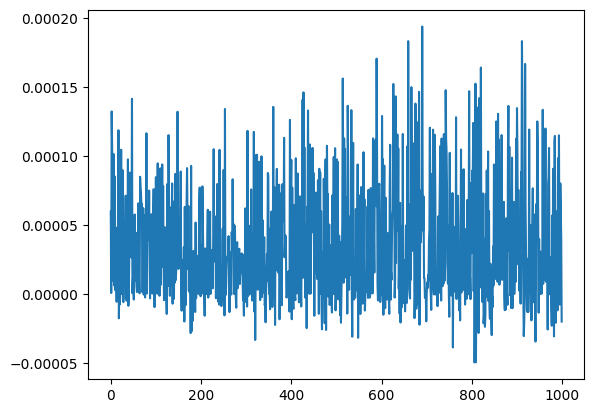

In [13]:
%run -i ../../models/signature_regression.py
plt.plot(l21)
np.mean(l21)

In [14]:
%run -i ../../data_generation/coarse_graining.py


/Users/munawarali/Documents/GitHub/SSISDE/data_generation/coarse_graining.py:8: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  sigma_pred[i] = sigma_pred_[i*M]


In [15]:
%run -i ../../models/coarse_diffusion_derivatives.py


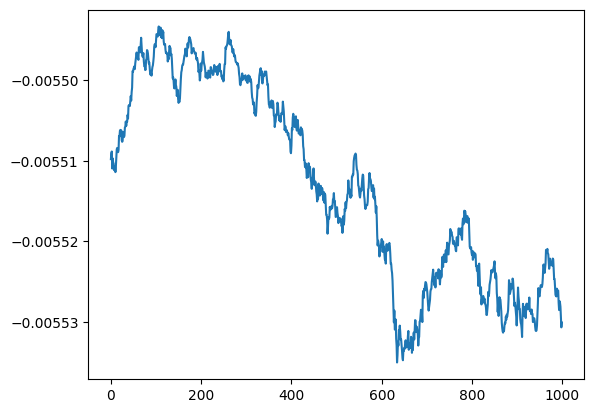

In [16]:
plt.plot(sigma_2prime)

## Predicting $\mu(X_t)$ by tuncating up to level-2 of iterated integrals

In [17]:
%run -i ../../models/drift_coefficients.py


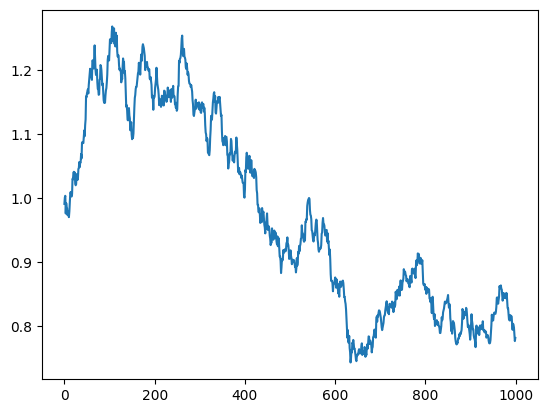

In [18]:
#plt.plot(b)
plt.plot(a)

In [19]:
%run -i ../../models/drift_recovery.py


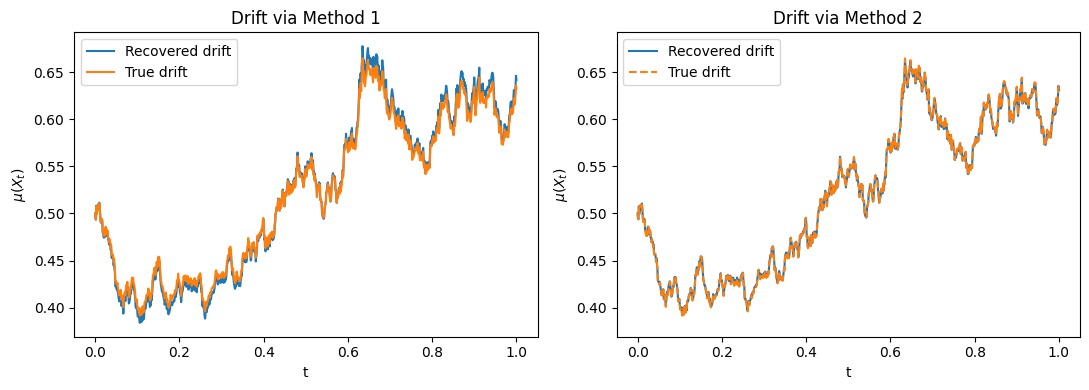

In [20]:
t_ = np.linspace(0, T, K)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(t_, mu_pred1, label="Recovered drift")
axes[0].plot(t_, mu_exact, label="True drift")
axes[0].set_title("Drift via Method 1")
axes[0].set_xlabel("t")
axes[0].set_ylabel("$\mu(X_t)$")
axes[0].legend()
axes[1].plot(t_, mu_pred2, label="Recovered drift")
axes[1].set_title("Drift via Method 2")
axes[1].plot(t_, mu_exact, '--', label="True drift")
axes[1].set_xlabel("t")
axes[1].set_ylabel("$\mu(X_t)$")
axes[1].legend()
axes[1].set_ylim(axes[0].get_ylim())

plt.tight_layout()
plt.savefig("Drift_via_Euler_BS.png", bbox_inches='tight', dpi=300)
plt.show()

## Drift recovery from ODE2

Run the ODE2 recovery with the existing coarse data and compare `mu_pred11` with the actual drift `mu_exact`. The initial conditions are `mu_0` and `r`, as in the supplied code.


In [21]:
%run -i ../../models/drift_recovery_from_ODE2.py


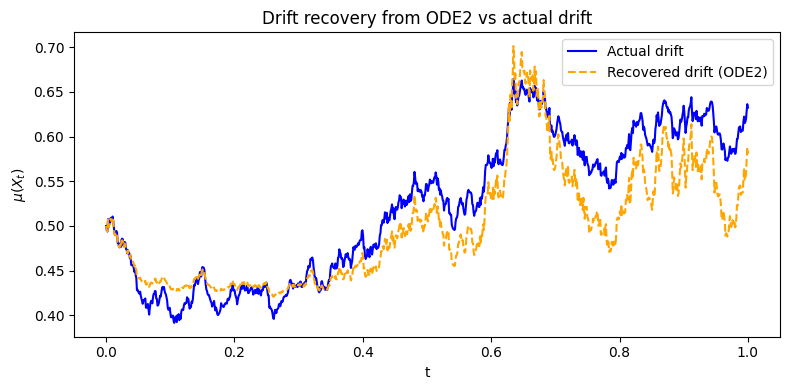

ODE2 drift MSE: 0.0013427
ODE2 drift RMSE: 0.0366429


In [22]:
plt.figure(figsize=(8, 4))
plt.plot(t_, mu_exact, label="Actual drift", color="blue")
plt.plot(t_, mu_pred11, '--', label="Recovered drift (ODE2)", color="orange")
plt.xlabel("t")
plt.ylabel(r"$\mu(X_t)$")
plt.title("Drift recovery from ODE2 vs actual drift")
plt.legend()
plt.tight_layout()
plt.savefig("Drift_via_ODE2_BS.png", bbox_inches='tight', dpi=300)
plt.show()

ode2_drift_mse = mean_squared_error(mu_exact, mu_pred11)
print(f"ODE2 drift MSE: {ode2_drift_mse:.6g}")
print(f"ODE2 drift RMSE: {np.sqrt(ode2_drift_mse):.6g}")


##Predicting P-Brownian motion

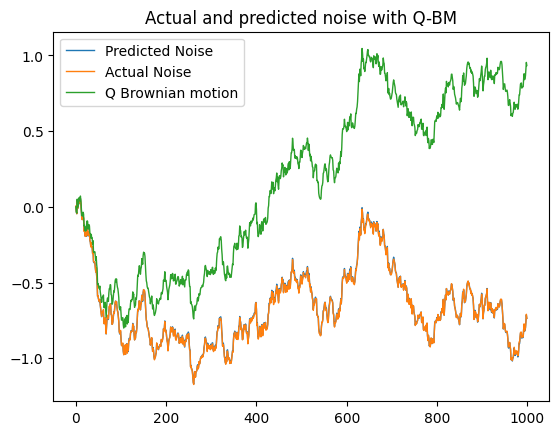

In [23]:
%run -i ../../models/p_brownian_motion.py
plt.plot(BP, label="Predicted Noise", linewidth=1)
plt.plot(W, label="Actual Noise", linewidth=1)
plt.plot(BQ, label="Q Brownian motion", linewidth=1)
plt.title("Actual and predicted noise with Q-BM")
plt.legend()
plt.savefig(f"{model}_Actual and predicted noise with Q-BM.png", bbox_inches='tight', dpi=300)
plt.show()

MSE: 5.244e-09
μ(X) = 0.503773*X
σ(X) = 0.00323797 + 0.295761*X
[CV best] alpha=0.000387, l1_ratio (rho)=0.85


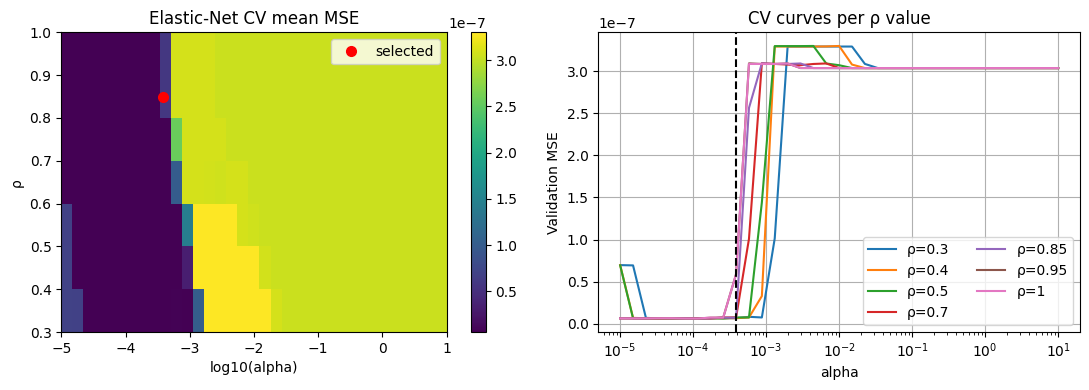

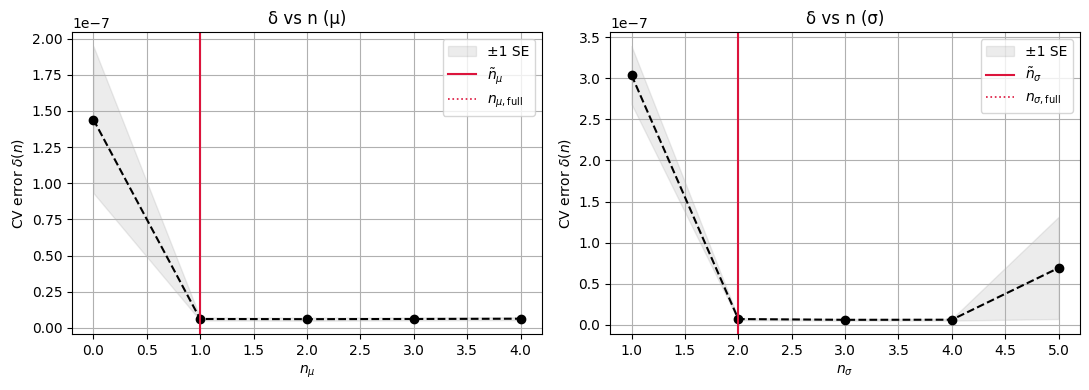

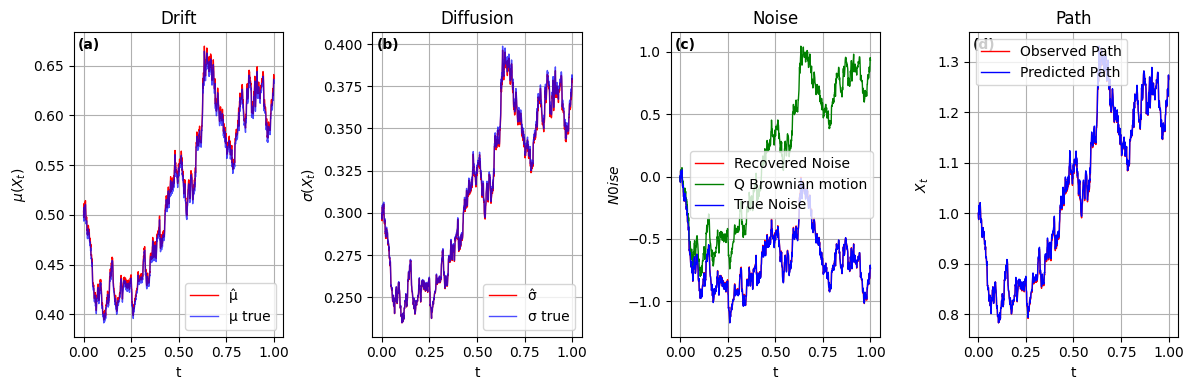

In [24]:
%run -i ../../models/stochastic_sindy.py
identifier = StochSINDy(
    mu_deg=5, si_deg=5,
    pen="elasticnet",
    use_cv=True, k=7,
    alphas=np.geomspace(1e-5, 1e1, 35),
    rhos=[0.3, 0.4, 0.5, 0.7, 0.85, 0.95, 1.0],
    #rhos=[0.7, 0.85, 0.95, 1.0],
    use_1se=True
)
identifier.fit(S, BP, dt)
identifier.show()
identifier.plot_cv()
identifier.plot_size(count_bias=True)
identifier.plot_results(S, BP, BQ, W, mu_true=mu_exact, si_true=sigma_exact)